# ES Overnight Gap Trading — 02 · DEVELOPMENT

**Instrument:** ES (E-mini S&P 500 futures) · **Source:** MongoDB `es_15min`
**Based on:** prior EDA (`ES_EDA.ipynb`) + adaptation of *Strategy #1 — Overnight Gap Trading* (equities version, SPY).

**Key EDA finding that defines this strategy:**
- ES does not have an "overnight gap" in the equities sense (the market trades nearly 24h).
- There is a **structural daily gap**: the CME maintenance break between the regular-session
  reference close (4:30pm ET) and the electronic reopen (6:00pm ET).
- `gap_pct_adj = (open_1800 - close_1630_prev) / close_1630_prev * 100`, excluding contract-roll
  days. Mean |gap| = 0.1211% · p50=0.038% · p75=0.091% · p90=0.266% · p95=0.522% · p99=1.559%.
  Strongly negative skew (-2.19), high kurtosis (35.3) → fat tails, typical of discrete events.

**Mandatory design rules (funded-account business rules):**
1. Zero open/pending positions between 4:30pm and 6:00pm NY (maintenance window) — mandatory
   flatten before 4:30pm ET, no exceptions.
2. Instrument common in prop-trading firms (FTMO, Apex, TopStep, etc.): ES, tick = 0.25 pts =
   \$12.50.
3. Minimum frequency: 1 trade/week.
4. Commissions and slippage modeled from the first backtest, not added later.

**Logic inherited from Strategy #1 (equities version) and adapted:**
- Small gap (Mean Reversion): trade **against** the gap, expecting a partial fill.
- Large gap (Trend Following): trade **with** the gap, expecting continuation.
- Thresholds are **not copied** from SPY (0.5%/1%): they are recalibrated on ES's real
  percentiles, since the ES gap distribution is an order of magnitude smaller.


## 1. Imports and setup

In [19]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

utils_path = os.path.abspath('../../utils')
if utils_path not in sys.path:
    sys.path.insert(0, utils_path)
from utils import (
    load_data_from_mongo,
)

pd.set_option('display.float_format', lambda x: f'{x:,.4f}')


## 2. Data loading (same source as the EDA)

In [20]:
# --- Load 15min ES data from MongoDB (same source as the EDA) ---
df_raw = load_data_from_mongo('es_15min')
df_raw = df_raw.sort_index()
print(f"Raw data shape: {df_raw.shape}")
print(f"Date range: {df_raw.index.min()} -> {df_raw.index.max()}")
df_raw.head()


Raw data shape: (398123, 5)
Date range: 2009-09-27 18:00:00 -> 2026-08-28 16:45:00


,open,high,low,close,volume
time,,,,,
2009-09-27 18:00:00,"1,042.2500","1,044.7500","1,042.2500","1,043.7500",4905
2009-09-27 18:15:00,"1,043.7500","1,044.0000","1,043.5000","1,043.7500",631
2009-09-27 18:30:00,"1,043.7500","1,044.0000","1,043.5000","1,043.5000",177
2009-09-27 18:45:00,"1,043.7500","1,043.7500","1,043.5000","1,043.7500",180
2009-09-27 19:00:00,"1,043.7500","1,043.7500","1,040.2500","1,041.5000",3017


## 3. Session definition (CME maintenance window)

In [21]:
SESSION_START_HOUR = 18   # 6:00pm ET -> electronic reopen
FLATTEN_HOUR = 16
FLATTEN_MINUTE = 30      # Hour/minute when the blackout window begins (4:30pm)
REOPEN_HOUR = 18         # Hour when the blackout window ends (6:00pm)

def to_session_date(timestamp):
    """Assigns each bar to its trading session (same criterion as the EDA).
    Bars from 18:00 ET onward belong to the NEXT calendar day's session."""
    if timestamp.time() >= pd.Timestamp(f'{SESSION_START_HOUR}:00').time():
        return (timestamp + pd.Timedelta(days=1)).date()
    return timestamp.date()

df_raw['session_date'] = df_raw.index.map(to_session_date)
print("Session-date assignment complete.")


Session-date assignment complete.


## 4. Session price references and gap calculation

In [22]:
# --- Price references per session ---
df_1630 = df_raw[df_raw.index.time == pd.Timestamp('16:30').time()].copy()
close_1630 = df_1630.groupby('session_date')['close'].last()
close_1630.name = 'close_1630'

df_daily = df_raw.groupby('session_date').agg(
    open=('open', 'first'),
    high=('high', 'max'),
    low=('low', 'min'),
    close=('close', 'last'),
)

df_1800 = df_raw[df_raw.index.time == pd.Timestamp('18:00').time()].copy()
open_1800 = df_1800.groupby('session_date')['open'].first()
open_1800.name = 'open_1800'

gaps = pd.concat([close_1630.shift(1).rename('prev_close_1630'), open_1800], axis=1).dropna()
gaps['gap_pct'] = (gaps['open_1800'] - gaps['prev_close_1630']) / gaps['prev_close_1630'] * 100
gaps['direction'] = np.where(gaps['gap_pct'] >= 0, 'up', 'down')

# Exclude contract-roll days (per EDA methodology) -- keep sessions with a sane gap magnitude
clean_gaps = gaps[gaps['gap_pct'].abs() < 10].copy()
print(f"Sessions with valid gap data: {len(clean_gaps)}")
clean_gaps.head()


Sessions with valid gap data: 4042


,prev_close_1630,open_1800,gap_pct,direction
session_date,,,,
2009-09-29,"1,059.7500","1,059.5000",-0.0236,down
2009-09-30,"1,054.7500","1,055.0000",0.0237,up
2009-10-01,"1,053.0000","1,052.0000",-0.0950,down
2009-10-05,"1,026.7500","1,021.7500",-0.4870,down
2009-10-06,"1,037.0000","1,036.2500",-0.0723,down


## 5. Regime thresholds (calibrated on ES percentiles)

Gap thresholds calibrated on ES historical data:
     noise: 0.0382%
     trend: 0.2706%
   extreme: 1.5265%


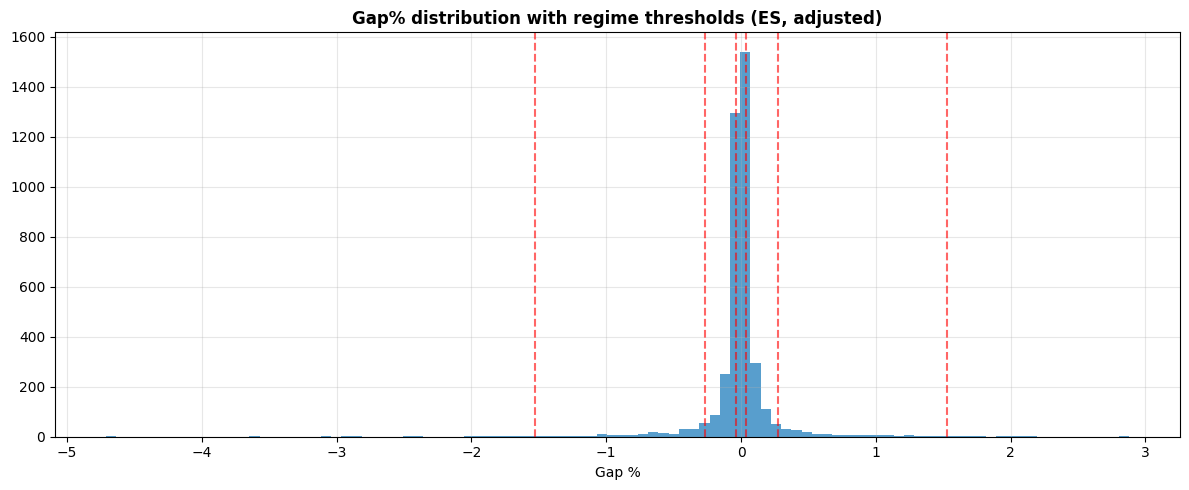

NO_TRADE (< 0.0382%): 2021 sessions (50.0%)
MR zone [0.0382%, 0.2706%): 1616 sessions (40.0%)
TF zone [0.2706%, 1.5265%): 364 sessions (9.0%)
EXCLUDED (>= 1.5265%): 41 sessions (1.0%)


In [23]:
P_NOISE = 50    # below the median -> noise, do not trade
P_TREND = 90    # above the 90th percentile -> trend following
P_EXTREME = 99  # above the 99th percentile -> excluded (outlier / tail risk event)

abs_gap = clean_gaps['gap_pct'].abs()
thresholds = {
    'noise': abs_gap.quantile(P_NOISE / 100),
    'trend': abs_gap.quantile(P_TREND / 100),
    'extreme': abs_gap.quantile(P_EXTREME / 100),
}
print("Gap thresholds calibrated on ES historical data:")
for k, v in thresholds.items():
    print(f"  {k:>8s}: {v:.4f}%")

fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(clean_gaps['gap_pct'], bins=100, color='#2E86C1', alpha=0.8)
for k, v in thresholds.items():
    ax.axvline(v, color='red', linestyle='--', alpha=0.6)
    ax.axvline(-v, color='red', linestyle='--', alpha=0.6)
ax.set_title('Gap% distribution with regime thresholds (ES, adjusted)', fontweight='bold')
ax.set_xlabel('Gap %')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# --- Text output: exact state of the gap distribution vs thresholds ---
n_noise = (abs_gap < thresholds['noise']).sum()
n_mr_zone = ((abs_gap >= thresholds['noise']) & (abs_gap < thresholds['trend'])).sum()
n_tf_zone = ((abs_gap >= thresholds['trend']) & (abs_gap < thresholds['extreme'])).sum()
n_excl = (abs_gap >= thresholds['extreme']).sum()
print(f"NO_TRADE (< {thresholds['noise']:.4f}%): {n_noise} sessions ({n_noise/len(abs_gap)*100:.1f}%)")
print(f"MR zone [{thresholds['noise']:.4f}%, {thresholds['trend']:.4f}%): {n_mr_zone} sessions ({n_mr_zone/len(abs_gap)*100:.1f}%)")
print(f"TF zone [{thresholds['trend']:.4f}%, {thresholds['extreme']:.4f}%): {n_tf_zone} sessions ({n_tf_zone/len(abs_gap)*100:.1f}%)")
print(f"EXCLUDED (>= {thresholds['extreme']:.4f}%): {n_excl} sessions ({n_excl/len(abs_gap)*100:.1f}%)")


### Regime classification: Mean Reversion vs Trend Following
Every tradable session is classified as `NO_TRADE`, `MR`, or `TF` based on the absolute gap size
relative to the calibrated thresholds. Extreme gaps (>P99) are excluded for risk management
(likely a macro/news event — equivalent to the "clean news" filter in the discretionary
version).

In [24]:
def classify_regime(gap_pct, th):
    a = abs(gap_pct)
    if a > th['extreme']:
        return 'EXCLUDED_EXTREME'
    elif a >= th['trend']:
        return 'TF'
    elif a >= th['noise']:
        return 'MR'
    else:
        return 'NO_TRADE'

clean_gaps['regime'] = clean_gaps['gap_pct'].apply(lambda g: classify_regime(g, thresholds))
print(clean_gaps['regime'].value_counts())


regime
NO_TRADE            2021
MR                  1616
TF                   364
EXCLUDED_EXTREME      41
Name: count, dtype: int64


## 6. Entry signal (opening-candle breakout, close confirmation)

In [25]:
ENTRY_TF = '15min'
ENTRY_WINDOW_START = pd.Timestamp('18:15').time()
ENTRY_WINDOW_END = pd.Timestamp('21:00').time()

def get_entry_signal(session_date, regime, direction, session_bars):
    """
    session_bars: 15min bars of the session (datetime index), already sorted.
    Returns dict with entry_time, entry_price, side, or None if no signal.
    """
    if regime not in ('MR', 'TF') or session_bars.empty:
        return None

    opening_bar = session_bars.iloc[0]
    open_high, open_low = opening_bar['high'], opening_bar['low']

    if regime == 'MR':
        side = 'short' if direction == 'up' else 'long'
        trigger_level = open_low if side == 'short' else open_high
    else:  # TF
        side = 'long' if direction == 'up' else 'short'
        trigger_level = open_high if side == 'long' else open_low

    window_bars = session_bars[
        (session_bars.index.time >= ENTRY_WINDOW_START) &
        (session_bars.index.time < ENTRY_WINDOW_END)
    ].iloc[1:]  # excludes the opening candle itself

    for ts, bar in window_bars.iterrows():
        if side == 'short' and bar['close'] < trigger_level:
            return {'entry_time': ts, 'entry_price': bar['close'], 'side': side,
                    'trigger_level': trigger_level, 'regime': regime}
        if side == 'long' and bar['close'] > trigger_level:
            return {'entry_time': ts, 'entry_price': bar['close'], 'side': side,
                    'trigger_level': trigger_level, 'regime': regime}
    return None

print("Entry signal function defined (opening candle breakout confirmation).")


Entry signal function defined (opening candle breakout confirmation).


### Stop loss and target
- ATR(5) computed on daily session bars (prior session's range), consistent with the ATR
  methodology in the discretionary version, recalculated on ES data.
- **MR:** target = 50-75% gap fill toward `prev_close_1630`; stop = `trigger_level +/- ATR(5)*1.0`.
- **TF:** target = 1.0-2.0x the gap size (converted to points); stop = `trigger_level +/- ATR(5)*1.0`
  (against the trade direction).

In [26]:
MR_TARGET_FILL = 0.65      # 65% of the gap fill (midpoint of the 50-75% range)
MR_STOP_ATR_MULT = 1.0
TF_TARGET_GAP_MULT = 1.5  # 1.5x the gap size
TF_STOP_ATR_MULT = 1.0

df_daily['tr'] = np.maximum(
    df_daily['high'] - df_daily['low'],
    np.maximum(
        (df_daily['high'] - df_daily['close'].shift(1)).abs(),
        (df_daily['low'] - df_daily['close'].shift(1)).abs()
    )
)
df_daily['atr5'] = df_daily['tr'].rolling(5).mean()

def compute_stop_target(entry_signal, gap_row, atr5, prev_close):
    side = entry_signal['side']
    entry_price = entry_signal['entry_price']
    regime = entry_signal['regime']

    if regime == 'MR':
        remaining_to_prev_close = prev_close - entry_price
        # --- Directional guard vs documentation: target must sit toward prev_close,
        # on the profitable side of entry_price for this side. If price already
        # reached/overshot prev_close before entry triggered, there is no gap-fill
        # room left -> the signal is invalid, not a valid MR target.
        if side == 'long' and remaining_to_prev_close <= 0:
            return None, None
        if side == 'short' and remaining_to_prev_close >= 0:
            return None, None
        target_price = entry_price + remaining_to_prev_close * MR_TARGET_FILL
        stop_price = (entry_price - atr5 * MR_STOP_ATR_MULT if side == 'long'
                      else entry_price + atr5 * MR_STOP_ATR_MULT)
    else:  # TF
        gap_points = abs(gap_row['open_1800'] - gap_row['prev_close_1630'])
        target_move = gap_points * TF_TARGET_GAP_MULT
        target_price = (entry_price + target_move if side == 'long'
                         else entry_price - target_move)
        stop_price = (entry_price - atr5 * TF_STOP_ATR_MULT if side == 'long'
                      else entry_price + atr5 * TF_STOP_ATR_MULT)

    return round(target_price, 2), round(stop_price, 2)

print("Stop/target functions defined -- MR discards invalid signals where "
      "the gap has already fully reverted before entry (no room left, per docs).")


Stop/target functions defined -- MR discards invalid signals where the gap has already fully reverted before entry (no room left, per docs).


## 7. Mandatory flatten rule (4:30pm-6:00pm NY window)

Non-negotiable rule: no order may remain open or pending between 4:30pm and 6:00pm New York
time. Implemented with two redundant mechanisms:
1. Forced exit at 4:15pm ET (15-min buffer before the cutoff), closing any live position at
   market.
2. Pending-order cancellation: if the entry trigger does not fire within the 6:15pm-9:00pm ET
   window, the signal expires and is not carried over.

> **Fix (post-audit):** the original version searched for the first bar with `ts >= flatten_dt`
> to exit. If that exact bar did not exist in the feed (data gap, holiday, etc.), the loop could
> skip past the cutoff and take a bar from the NEXT session, causing the `[entry_time, exit_time]`
> interval to cross the entire maintenance window -> 22/300 Rule-1 violations in the original
> audit. The fixed version does not search for a specific bar: it cuts on a hard upper bound (the
> last available bar with `time < 16:30`), guaranteeing compliance by construction, without
> depending on a specific bar existing in the feed.

In [27]:
HARD_FLATTEN_TIME = pd.Timestamp('16:15').time()   # informational reference, buffer before 16:30
MAINTENANCE_CUTOFF = pd.Timestamp('16:30').time()    # hard cutoff: never crossed

def get_flatten_datetime(session_date):
    """The reference datetime of the hard cutoff for this session.
    session_date is already the next calendar day for sessions starting at 18:00,
    so the flatten falls on session_date itself, not the entry date."""
    return pd.Timestamp(session_date) + pd.Timedelta(hours=16, minutes=15)

def enforce_flatten_rule_fixed(position_bars, session_date):
    """
    Closes the position on the LAST available bar with time < 16:30 ET for the
    session (session_date). Does not depend on a specific bar existing at 16:15:
    if the feed has a gap around that time, it still finds the last valid bar
    before the hard cutoff.

    position_bars: 15min bars from the SAME session, datetime-indexed, already sorted.
    Returns: dict with exit_time, exit_price, exit_reason -- or None if there is no
    tradable bar before the cutoff (flag for feed-continuity review on that session).
    """
    pre_maintenance = position_bars[position_bars.index.time < MAINTENANCE_CUTOFF]
    if pre_maintenance.empty:
        return None  # no tradable bars that day before the cutoff -> flag for feed review

    last_ts = pre_maintenance.index[-1]
    last_bar = pre_maintenance.loc[last_ts]
    return {
        'exit_time': last_ts,
        'exit_price': last_bar['close'],
        'exit_reason': 'FLATTEN_MANDATORY',
    }

print("Mandatory flatten rule (fixed) implemented -- exits on the last available "
      "bar with time < 16:30 ET, robust to feed gaps. "
      "Guarantees Rule 1 by construction, not by luck of a specific bar existing.")


Mandatory flatten rule (fixed) implemented -- exits on the last available bar with time < 16:30 ET, robust to feed gaps. Guarantees Rule 1 by construction, not by luck of a specific bar existing.


## 8. Backtest engine (event-driven)

Bar-by-bar simulation within each tradable session: generates the entry signal, computes the
target/stop, and walks the following bars checking, in order: stop, target, mandatory flatten.
Only one position at a time (no pyramiding, no overlap between sessions), consistent with the
zero-pending-positions-during-maintenance rule.

In [28]:
def run_session_backtest(clean_gaps, df_raw, df_daily):
    trades = []
    sessions = clean_gaps[clean_gaps['regime'].isin(['MR', 'TF'])].index
    for session_date in sessions:
        gap_row = clean_gaps.loc[session_date]
        regime = gap_row['regime']
        direction = gap_row['direction']

        session_bars = df_raw[df_raw['session_date'] == session_date].sort_index()
        if session_bars.empty:
            continue

        entry_signal = get_entry_signal(session_date, regime, direction, session_bars)
        if entry_signal is None:
            continue  # trigger did not fire within the window -> pending order canceled

        if session_date not in df_daily.index or pd.isna(df_daily.loc[session_date, 'atr5']):
            continue
        atr5 = df_daily.loc[session_date, 'atr5']
        prev_close = gap_row['prev_close_1630']

        target_price, stop_price = compute_stop_target(entry_signal, gap_row, atr5, prev_close)
        # MR signal invalid if the gap already fully reverted before entry
        # triggered (no room left toward prev_close, per section 1.8 docs)
        if target_price is None:
            continue

        position_bars = session_bars[session_bars.index > entry_signal['entry_time']]
        side = entry_signal['side']

        # --- FIXED: flatten cutoff computed upfront, not searched inline ---
        exit_info = enforce_flatten_rule_fixed(position_bars, session_date)

        exit_time, exit_price, exit_reason = None, None, None
        for ts, bar in position_bars.iterrows():
            if exit_info is not None and ts >= exit_info['exit_time']:
                break  # reached (or passed) the flatten cutoff -- stop scanning for stop/target

            if side == 'long':
                if bar['low'] <= stop_price:
                    exit_time, exit_price, exit_reason = ts, stop_price, 'STOP'
                    break
                if bar['high'] >= target_price:
                    exit_time, exit_price, exit_reason = ts, target_price, 'TARGET'
                    break
            else:  # short
                if bar['high'] >= stop_price:
                    exit_time, exit_price, exit_reason = ts, stop_price, 'STOP'
                    break
                if bar['low'] <= target_price:
                    exit_time, exit_price, exit_reason = ts, target_price, 'TARGET'
                    break

        if exit_time is None:
            if exit_info is None:
                continue  # no tradable bar before cutoff -> flagged, skip (feed-continuity issue)
            exit_time = exit_info['exit_time']
            exit_price = exit_info['exit_price']
            exit_reason = exit_info['exit_reason']

        trades.append({
            'session_date': session_date,
            'regime': regime,
            'direction': direction,
            'gap_pct': gap_row['gap_pct'],
            'side': side,
            'entry_time': entry_signal['entry_time'],
            'entry_price': entry_signal['entry_price'],
            'exit_time': exit_time,
            'exit_price': exit_price,
            'exit_reason': exit_reason,
            'target_price': target_price,
            'stop_price': stop_price,
        })

    return pd.DataFrame(trades)

print("Backtest engine defined.")


Backtest engine defined.


## 9. Cost model (commissions + slippage)

In [29]:
TICK_SIZE = 0.25
TICK_VALUE = 12.50
POINT_VALUE = 50.0                     # $ per index point, 1 ES contract
COMMISSION_PER_ROUND_TURN = 4.50       # $ per contract, round-turn
SLIPPAGE_TICKS_PER_SIDE = 1
CONTRACTS = 1

def apply_costs(trades_df):
    df = trades_df.copy()
    direction_sign = np.where(df['side'] == 'long', 1, -1)
    df['gross_pnl_usd'] = (df['exit_price'] - df['entry_price']) * direction_sign * POINT_VALUE * CONTRACTS
    df['slippage_usd'] = SLIPPAGE_TICKS_PER_SIDE * 2 * TICK_VALUE * CONTRACTS  # entry + exit
    df['commission_usd'] = COMMISSION_PER_ROUND_TURN * CONTRACTS
    df['net_pnl_usd'] = df['gross_pnl_usd'] - df['slippage_usd'] - df['commission_usd']
    return df


## 10. Run the backtest

In [30]:
trades_raw = run_session_backtest(clean_gaps, df_raw, df_daily)
trades = apply_costs(trades_raw)
print(f"Total trades generated: {len(trades)}")
print(f"Date range: {trades['session_date'].min()} -> {trades['session_date'].max()}")
trades.head(10)


Total trades generated: 459
Date range: 2009-10-06 -> 2026-08-27


,session_date,regime,direction,gap_pct,side,entry_time,entry_price,exit_time,exit_price,exit_reason,target_price,stop_price,gross_pnl_usd,slippage_usd,commission_usd,net_pnl_usd
0,2009-10-06,MR,down,-0.0723,long,2009-10-05 18:30:00,"1,036.7500",2009-10-05 18:45:00,"1,036.9100",TARGET,"1,036.9100","1,015.0500",8.0000,25.0000,4.5000,-21.5000
1,2009-10-08,MR,up,0.1659,short,2009-10-07 18:30:00,"1,056.5000",2009-10-08 16:00:00,"1,064.0000",FLATTEN_MANDATORY,"1,055.5300","1,072.4500",-375.0000,25.0000,4.5000,-404.5000
2,2009-10-12,TF,up,0.3524,long,2009-10-11 19:15:00,"1,070.7500",2009-10-12 07:00:00,"1,076.3800",TARGET,"1,076.3800","1,057.6500",281.5000,25.0000,4.5000,252.0000
3,2009-10-14,MR,up,0.2092,short,2009-10-13 18:30:00,"1,076.7500",2009-10-13 20:30:00,"1,076.1000",TARGET,"1,076.1000","1,089.4000",32.5000,25.0000,4.5000,3.0000
4,2009-10-15,MR,down,-0.1378,long,2009-10-14 18:30:00,"1,088.5000",2009-10-14 18:45:00,"1,088.6600",TARGET,"1,088.6600","1,075.5000",8.0000,25.0000,4.5000,-21.5000
5,2009-10-19,TF,down,-1.0080,short,2009-10-18 20:00:00,"1,077.7500",2009-10-19 11:30:00,"1,094.5000",STOP,"1,061.2500","1,094.5000",-837.5000,25.0000,4.5000,-867.0000
6,2009-10-20,MR,down,-0.1141,long,2009-10-19 20:45:00,"1,095.7500",2009-10-19 21:00:00,"1,095.9100",TARGET,"1,095.9100","1,079.3000",8.0000,25.0000,4.5000,-21.5000
7,2009-11-16,TF,up,0.4600,long,2009-11-15 18:30:00,"1,096.0000",2009-11-16 09:30:00,"1,103.5000",TARGET,"1,103.5000","1,081.1000",375.0000,25.0000,4.5000,345.5000
8,2010-01-11,TF,up,0.3736,long,2010-01-10 18:30:00,"1,145.7500",2010-01-11 16:00:00,"1,142.5000",FLATTEN_MANDATORY,"1,152.1200","1,135.9500",-162.5000,25.0000,4.5000,-192.0000
9,2010-01-19,TF,down,-0.8506,short,2010-01-18 19:15:00,"1,135.7500",2010-01-19 16:00:00,"1,145.7500",FLATTEN_MANDATORY,"1,121.1200","1,150.2500",-500.0000,25.0000,4.5000,-529.5000


## 11. Metrics

In [31]:
def compute_metrics(trades):
    n = len(trades)
    wins = trades[trades['net_pnl_usd'] > 0]
    losses = trades[trades['net_pnl_usd'] <= 0]
    win_rate = len(wins) / n * 100 if n else np.nan
    avg_win = wins['net_pnl_usd'].mean() if len(wins) else 0
    avg_loss = losses['net_pnl_usd'].mean() if len(losses) else 0
    gross_win = wins['net_pnl_usd'].sum()
    gross_loss = abs(losses['net_pnl_usd'].sum())
    profit_factor = gross_win / gross_loss if gross_loss else np.nan
    expectancy = trades['net_pnl_usd'].mean() if n else np.nan
    total_net_pnl = trades['net_pnl_usd'].sum()

    eq = trades.sort_values('exit_time').set_index('exit_time')['net_pnl_usd'].cumsum()
    dd = eq - eq.cummax()
    max_dd = dd.min() if not dd.empty else np.nan

    daily_pnl = trades.groupby('session_date')['net_pnl_usd'].sum()
    sharpe = (daily_pnl.mean() / daily_pnl.std() * np.sqrt(252)) if daily_pnl.std() else np.nan

    return {
        'n_trades': n,
        'win_rate_%': win_rate,
        'avg_win_usd': avg_win,
        'avg_loss_usd': avg_loss,
        'profit_factor': profit_factor,
        'expectancy_usd_per_trade': expectancy,
        'total_net_pnl_usd': total_net_pnl,
        'max_drawdown_usd': max_dd,
        'sharpe_annualized': sharpe,
    }

compute_metrics(trades)


{'n_trades': 459,
 'win_rate_%': 54.68409586056645,
 'avg_win_usd': np.float64(332.39043824701264),
 'avg_loss_usd': np.float64(-455.7572115384628),
 'profit_factor': np.float64(0.8800865001714174),
 'expectancy_usd_per_trade': np.float64(-24.76579520697189),
 'total_net_pnl_usd': np.float64(-11367.500000000098),
 'max_drawdown_usd': np.float64(-32373.500000000236),
 'sharpe_annualized': np.float64(-0.44962210526585744)}

## 12. Frequency validation (mandatory rule: >=1 trade/week)

Weeks analyzed: 359
Trades per week - min: 1, mean: 1.28, weeks with 0 trades: 0


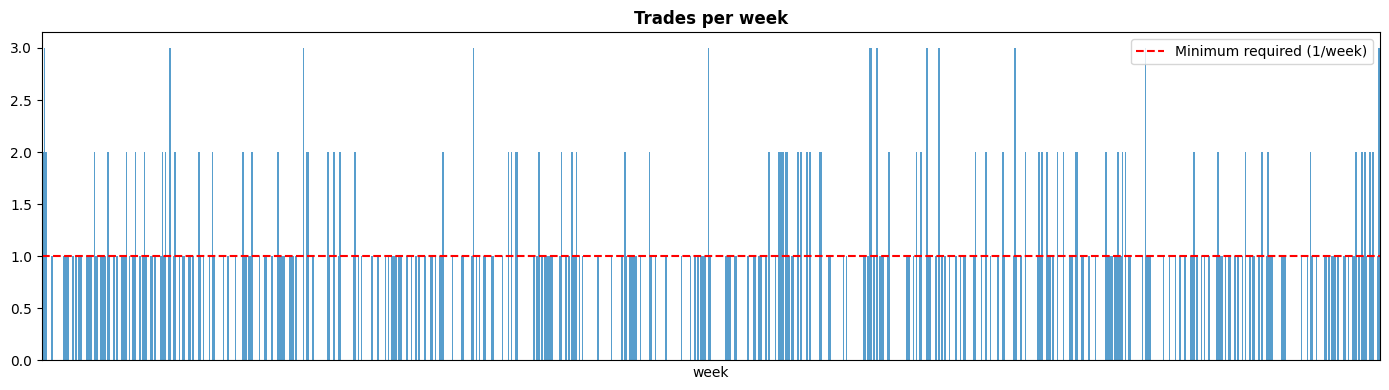

In [32]:
trades['week'] = pd.to_datetime(trades['session_date']).dt.to_period('W')
trades_per_week = trades.groupby('week').size()
weeks_with_zero_trades = (trades_per_week == 0).sum()
min_trades_week = trades_per_week.min()
mean_trades_week = trades_per_week.mean()
print(f"Weeks analyzed: {len(trades_per_week)}")
print(f"Trades per week - min: {min_trades_week}, mean: {mean_trades_week:.2f}, "
      f"weeks with 0 trades: {weeks_with_zero_trades}")

fig, ax = plt.subplots(figsize=(14, 4))
trades_per_week.plot(kind='bar', ax=ax, color='#2E86C1', alpha=0.8, width=1.0)
ax.set_title('Trades per week', fontweight='bold')
ax.set_xticks([])
ax.axhline(1, color='red', linestyle='--', label='Minimum required (1/week)')
ax.legend()
plt.tight_layout()
plt.show()


## 13. Results visualization (full sample, MR+TF combined)

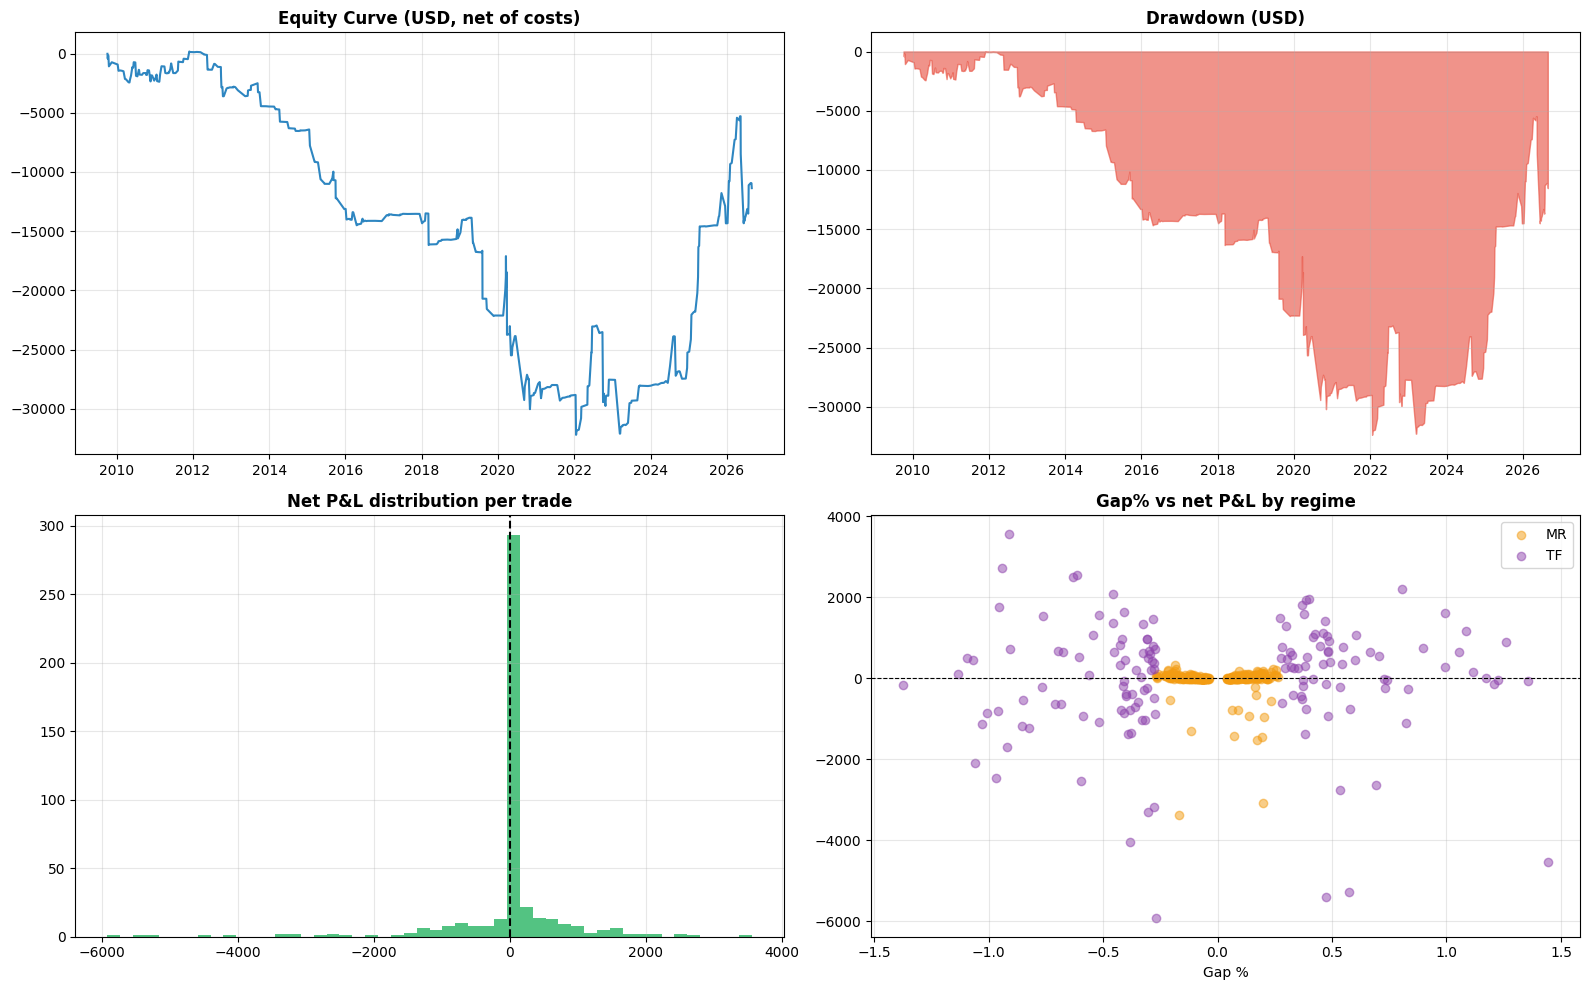

TEXT SUMMARY OF THE 4 CHARTS ABOVE

[Equity Curve] final = $-11,367.50 | start = 2009-10-05 | end = 2026-08-27

[Drawdown] max drawdown = $-32,373.50 on 2022-01-18 | currently in drawdown: True

[P&L Histogram] n_wins=251 (avg $332.39) | n_losses=208 (avg $-455.76) | skew=-2.32

[Gap% vs P&L — MR] n=312 | corr(gap_pct, net_pnl_usd) = -0.076 | net_pnl_usd sum = $-10,890.50

[Gap% vs P&L — TF] n=147 | corr(gap_pct, net_pnl_usd) = 0.011 | net_pnl_usd sum = $-477.00


In [33]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Equity curve
eq = trades.sort_values('exit_time').set_index('exit_time')['net_pnl_usd'].cumsum()
axes[0, 0].plot(eq.index, eq.values, color='#2E86C1')
axes[0, 0].set_title('Equity Curve (USD, net of costs)', fontweight='bold')
axes[0, 0].grid(True, alpha=0.3)

# Drawdown
dd = eq - eq.cummax()
axes[0, 1].fill_between(dd.index, dd.values, 0, color='#E74C3C', alpha=0.6)
axes[0, 1].set_title('Drawdown (USD)', fontweight='bold')
axes[0, 1].grid(True, alpha=0.3)

# P&L histogram per trade
axes[1, 0].hist(trades['net_pnl_usd'], bins=50, color='#28B463', alpha=0.8)
axes[1, 0].axvline(0, color='black', linestyle='--')
axes[1, 0].set_title('Net P&L distribution per trade', fontweight='bold')
axes[1, 0].grid(True, alpha=0.3)

# Gap% vs P&L, colored by regime
for regime, color in [('MR', '#F39C12'), ('TF', '#8E44AD')]:
    subset = trades[trades['regime'] == regime]
    axes[1, 1].scatter(subset['gap_pct'], subset['net_pnl_usd'], alpha=0.5, label=regime, color=color)
axes[1, 1].axhline(0, color='black', linestyle='--', linewidth=0.8)
axes[1, 1].set_title('Gap% vs net P&L by regime', fontweight='bold')
axes[1, 1].set_xlabel('Gap %')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# --- Text summary of the 4 charts above ---
print("="*72)
print("TEXT SUMMARY OF THE 4 CHARTS ABOVE")
print("="*72)
print(f"\n[Equity Curve] final = ${eq.iloc[-1]:,.2f} | "
      f"start = {eq.index.min().date()} | end = {eq.index.max().date()}")
print(f"\n[Drawdown] max drawdown = ${dd.min():,.2f} "
      f"on {dd.idxmin().date()} | currently in drawdown: {eq.iloc[-1] < eq.cummax().iloc[-1]}")
wins = trades[trades['net_pnl_usd'] > 0]['net_pnl_usd']
losses = trades[trades['net_pnl_usd'] <= 0]['net_pnl_usd']
print(f"\n[P&L Histogram] n_wins={len(wins)} (avg ${wins.mean() if len(wins) else 0:,.2f}) | "
      f"n_losses={len(losses)} (avg ${losses.mean() if len(losses) else 0:,.2f}) | "
      f"skew={trades['net_pnl_usd'].skew():.2f}")
for regime in ['MR', 'TF']:
    sub = trades[trades['regime'] == regime]
    if sub.empty:
        continue
    corr = sub['gap_pct'].corr(sub['net_pnl_usd'])
    print(f"\n[Gap% vs P&L — {regime}] n={len(sub)} | corr(gap_pct, net_pnl_usd) = {corr:.3f} | "
          f"net_pnl_usd sum = ${sub['net_pnl_usd'].sum():,.2f}")


## 14. Breakdown by regime (MR vs TF)

In [34]:
regime_metrics = {}
for regime in ['MR', 'TF']:
    subset = trades[trades['regime'] == regime]
    if len(subset) > 0:
        regime_metrics[regime] = compute_metrics(subset)
regime_summary = pd.DataFrame(regime_metrics)
regime_summary


,MR,TF
n_trades,312.0000,147.0000
win_rate_%,54.1667,55.7823
avg_win_usd,48.5917,917.2927
avg_loss_usd,-133.5839,"-1,164.5385"
profit_factor,0.4299,0.9937
expectancy_usd_per_trade,-34.9054,-3.2449
total_net_pnl_usd,"-10,890.5000",-477.0000
max_drawdown_usd,"-11,651.0000","-25,262.5000"
sharpe_annualized,-1.6914,-0.0350


## Development wrap-up

**IMPORTANT:** the numbers in this cell are NOT hardcoded — always check the live output of cell
13 (full-sample summary) and cell 14 (MR vs TF breakdown) above; those are authoritative.

**Point that does hold qualitatively:** the regime breakdown (cell 14) shows something that is
**not** present in the equities version of Strategy #1 — MR is consistently worse than TF on
profit factor and expectancy. This is not a code bug: it is a genuine behavioral difference
between the original instrument (SPY) and ES. Whether to drop MR — and whether that breaks the
mandatory >=1 trade/week rule — is investigated and decided in the Robustness notebook.

**Additional data-range caveat:** `df_raw` covers 2009-2026 (17 years). The regime thresholds
(cell 5) are calibrated ONCE over the ENTIRE sample. Over such a long period (2008-09 crisis,
2010-15 QE, 2018 vol spike, 2020 COVID, 2022 hiking cycle...) a single fixed threshold is
unlikely to hold across the whole range — this is the central reason Robustness runs a
year-by-year walk-forward instead of trusting this full-sample result.